# Experiment 5: Feature Extraction using SIFT



**Name:** Varsha Shivanand K

**USN:** 1RUA24CSE0516

**Sem:** 5

**Sec:** F

## Step 1: Install and import libraries

In [ ]:
!pip install -q opencv-python numpy matplotlib scikit-image

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


## Step 2: Load the grayscale image

In [ ]:
# ---------- Load the input image ----------
# Upload "input_image.png" (any JPG/PNG works, colour or grayscale) to the Colab Files panel.
# If the file is not found, the built-in scikit-image "camera" sample is used instead.
IMAGE_PATH = "input_image.png"

if os.path.exists(IMAGE_PATH):
    image = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    print("Loaded uploaded image:", IMAGE_PATH)
else:
    image = data.camera().astype(np.uint8)
    print("input_image.png not found -> using scikit-image camera sample")

print("Image size (H x W):", image.shape)

input_image.png not found -> using scikit-image camera sample
Image size (H x W): (512, 512)


## Step 3: Detect SIFT keypoints and compute descriptors

Number of keypoints: 791
Descriptor shape: (791, 128)
Descriptor length: 128


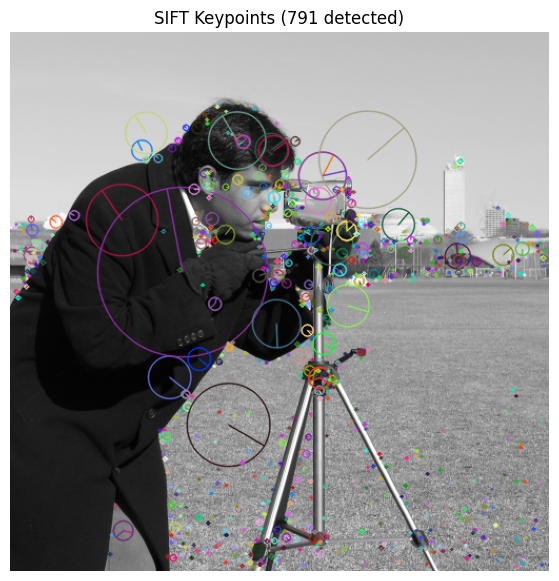

In [ ]:
sift = cv2.SIFT_create()

keypoints, descriptors = sift.detectAndCompute(image, None)

output = cv2.drawKeypoints(image, keypoints, None,
                           flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

print("Number of keypoints:", len(keypoints))
if descriptors is not None:
    print("Descriptor shape:", descriptors.shape)
    print("Descriptor length:", descriptors.shape[1])

plt.figure(figsize=(10, 7))
plt.imshow(output)
plt.title(f"SIFT Keypoints ({len(keypoints)} detected)")
plt.axis("off")
plt.show()

## Step 4: Inspect a few keypoints

In [ ]:
print(f"{'#':>3} {'x':>8} {'y':>8} {'size':>8} {'angle':>8} {'response':>10}")
for i, kp in enumerate(sorted(keypoints, key=lambda k: -k.response)[:10]):
    print(f"{i:>3} {kp.pt[0]:8.1f} {kp.pt[1]:8.1f} {kp.size:8.2f} {kp.angle:8.1f} {kp.response:10.4f}")

  #        x        y     size    angle   response
  0    181.3    200.5     9.61    194.5     0.1016
  1    181.3    200.5     9.61    352.1     0.1016
  2    285.7    333.7     3.48    186.9     0.0980
  3    280.5    251.4     7.60    333.1     0.0970
  4    176.0    179.4     6.99    339.0     0.0888
  5    294.1    347.9     3.08      6.0     0.0826
  6    294.1    347.9     3.08     98.6     0.0826
  7    320.7    152.1     5.23      6.9     0.0820
  8    292.9    222.7     4.83      4.8     0.0803
  9    292.9    222.7     4.83    166.8     0.0803


## Student Task 1: Number of detected keypoints

In [ ]:
print("Task 1 -> Keypoints detected in the original image:", len(keypoints))

Task 1 -> Keypoints detected in the original image: 791


## Student Task 2: Rotate the image by 30° and compare keypoints

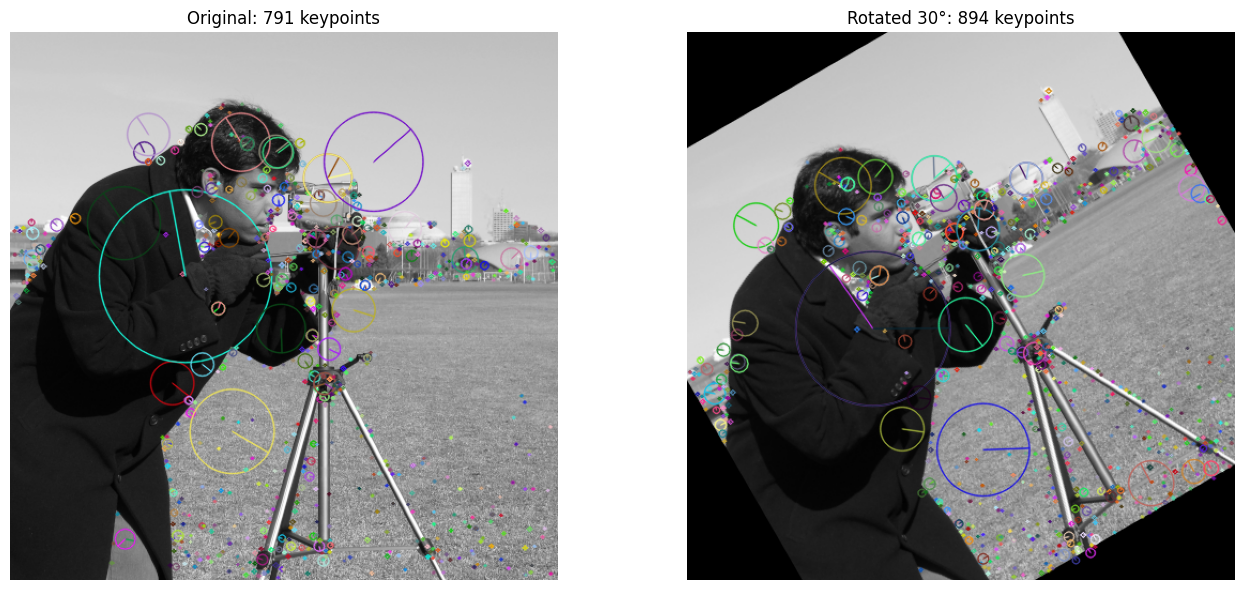

Original keypoints : 791
Rotated  keypoints : 894


In [ ]:
h, w = image.shape
M30 = cv2.getRotationMatrix2D((w // 2, h // 2), 30, 1.0)
rotated = cv2.warpAffine(image, M30, (w, h))

kp_rot, des_rot = sift.detectAndCompute(rotated, None)

out_orig = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
out_rot = cv2.drawKeypoints(rotated, kp_rot, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1); plt.imshow(out_orig); plt.title(f"Original: {len(keypoints)} keypoints"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(out_rot); plt.title(f"Rotated 30°: {len(kp_rot)} keypoints"); plt.axis("off")
plt.tight_layout(); plt.show()

print("Original keypoints :", len(keypoints))
print("Rotated  keypoints :", len(kp_rot))

## Student Task 3: Change the image scale

Scale 0.5: image (256, 256), keypoints = 241
Scale 1.0: image (512, 512), keypoints = 791
Scale 1.5: image (768, 768), keypoints = 2304


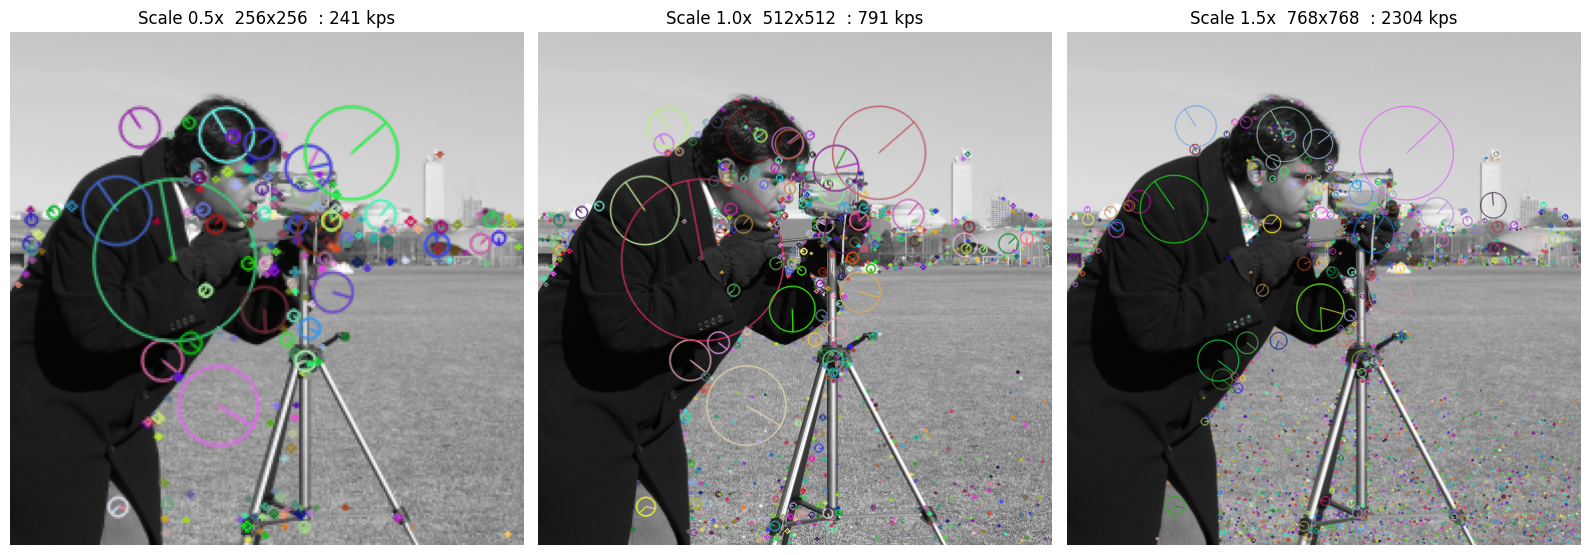

In [ ]:
scales = [0.5, 1.0, 1.5]
plt.figure(figsize=(16, 6))
for i, s in enumerate(scales, 1):
    scaled = cv2.resize(image, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
    kp_s, des_s = sift.detectAndCompute(scaled, None)
    vis = cv2.drawKeypoints(scaled, kp_s, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.subplot(1, 3, i); plt.imshow(vis)
    plt.title(f"Scale {s}x  {scaled.shape[1]}x{scaled.shape[0]}  : {len(kp_s)} kps"); plt.axis("off")
    print(f"Scale {s}: image {scaled.shape}, keypoints = {len(kp_s)}")
plt.tight_layout(); plt.show()

## Student Task 4: Verify the 128-dimensional descriptor

In [ ]:
print("Descriptor matrix shape:", descriptors.shape)
print("Rows (= keypoints)     :", descriptors.shape[0], "| keypoints:", len(keypoints))
print("Columns (= dimensions) :", descriptors.shape[1])
print("All descriptors 128-D? :", descriptors.shape[1] == 128 and descriptors.shape[0] == len(keypoints))
print("\nFirst descriptor (first 16 of 128 values):", descriptors[0][:16])

Descriptor matrix shape: (791, 128)
Rows (= keypoints)     : 791 | keypoints: 791
Columns (= dimensions) : 128
All descriptors 128-D? : True

First descriptor (first 16 of 128 values): [ 5.  1.  0.  1.  1.  0.  0.  0. 52.  1.  0.  0.  1.  0.  0.  0.]


## Student Task 5: SIFT feature matching (rotated image + Lowe's ratio test)

Keypoints in image 1: 791
Keypoints in image 2: 872
Total knn matches   : 791
Good matches        : 477


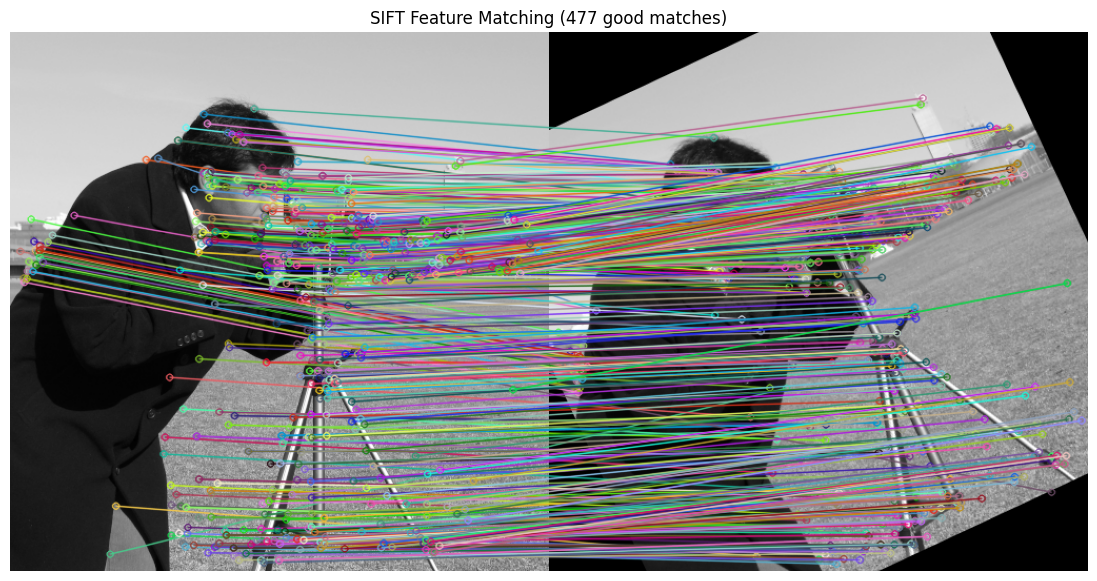

In [ ]:
img1 = image
h, w = img1.shape
M25 = cv2.getRotationMatrix2D((w // 2, h // 2), 25, 1.0)
img2 = cv2.warpAffine(img1, M25, (w, h))

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

good_matches = []
for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

result = cv2.drawMatches(img1, kp1, img2, kp2, good_matches, None,
                         flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

print("Keypoints in image 1:", len(kp1))
print("Keypoints in image 2:", len(kp2))
print("Total knn matches   :", len(matches))
print("Good matches        :", len(good_matches))

plt.figure(figsize=(14, 7))
plt.imshow(result)
plt.title(f"SIFT Feature Matching ({len(good_matches)} good matches)")
plt.axis("off")
plt.show()

## Matching under scale change (extra check)

Good matches (original vs 0.6x scaled): 242


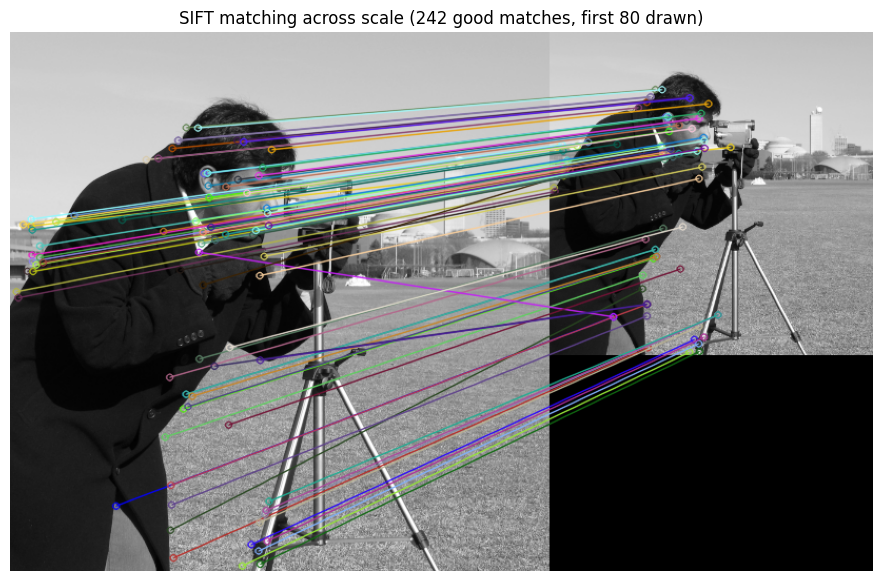

In [ ]:
img3 = cv2.resize(img1, None, fx=0.6, fy=0.6)
kp3, des3 = sift.detectAndCompute(img3, None)
good_scale = [m for m, n in (p for p in bf.knnMatch(des1, des3, k=2) if len(p) == 2)
              if m.distance < 0.75 * n.distance]
res2 = cv2.drawMatches(img1, kp1, img3, kp3, good_scale[:80], None,
                       flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
print("Good matches (original vs 0.6x scaled):", len(good_scale))
plt.figure(figsize=(14, 7)); plt.imshow(res2)
plt.title(f"SIFT matching across scale ({len(good_scale)} good matches, first 80 drawn)")
plt.axis("off"); plt.show()


## Student Task 6: Why is SIFT better than comparing raw pixel values?

Raw pixel comparison fails as soon as the image is rotated, resized, shifted or its brightness changes, because the same object no longer sits at the same pixel positions with the same values. SIFT detects keypoints at their own characteristic scale, assigns each one a dominant orientation, and builds a descriptor from normalised gradient histograms relative to that scale and orientation. This makes the descriptor invariant to scale and rotation and robust to illumination and small viewpoint changes, so the same physical point can be matched across different images.


## Result

SIFT keypoints and 128-dimensional local feature descriptors were extracted successfully. The keypoints were visualised, their behaviour under rotation and scale changes was studied, and feature matching with a Brute-Force matcher and Lowe's ratio test showed how SIFT descriptors find corresponding points between related images.